C:\Users\12518\anaconda\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │          25,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │              90 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 25,874 (101.07 KB)

 Trainable params: 25,874 (101.07 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.7055 - loss: 0.8829 - val_accuracy: 0.9307 - val_loss: 0.2397
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9362 - loss: 0.2195 - val_accuracy: 0.9452 - val_loss: 0.1899
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9499 - loss: 0.1669 - val_accuracy: 0.9514 - val_loss: 0.1632
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9592 - loss: 0.1401 - val_accuracy: 0.9565 - val_loss: 0.1482
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9640 - loss: 0.1195 - val_accuracy: 0.9573 - val_loss: 0.1495
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9683 - loss: 0.1043 - val_accuracy: 0.9577 - val_loss: 0.1459
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9719 - loss: 0.0949 - val_accuracy: 0.9615 - val_loss: 0.1333
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9741 - loss: 0.0847

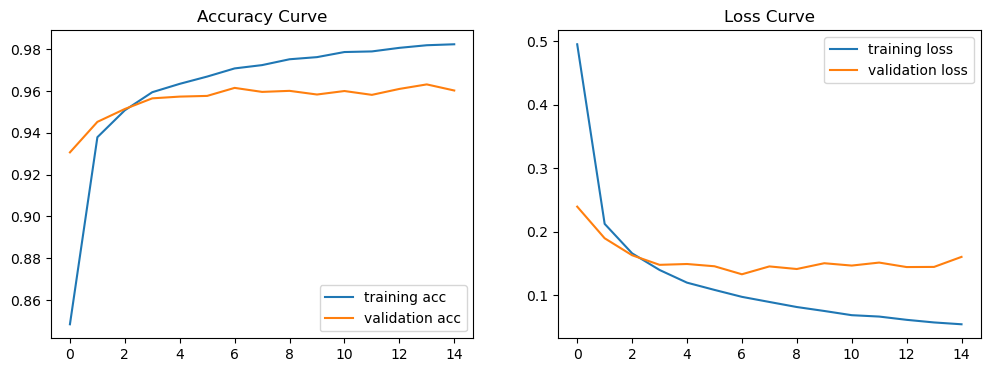

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


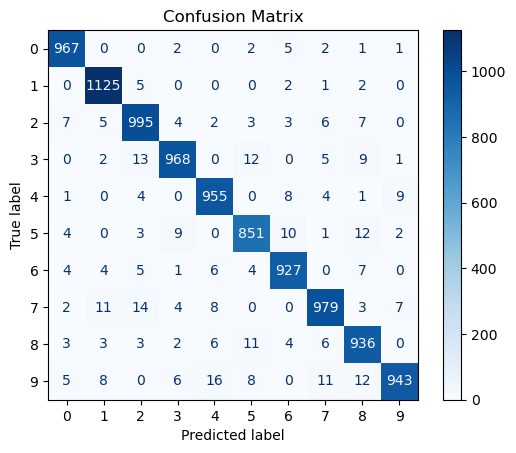

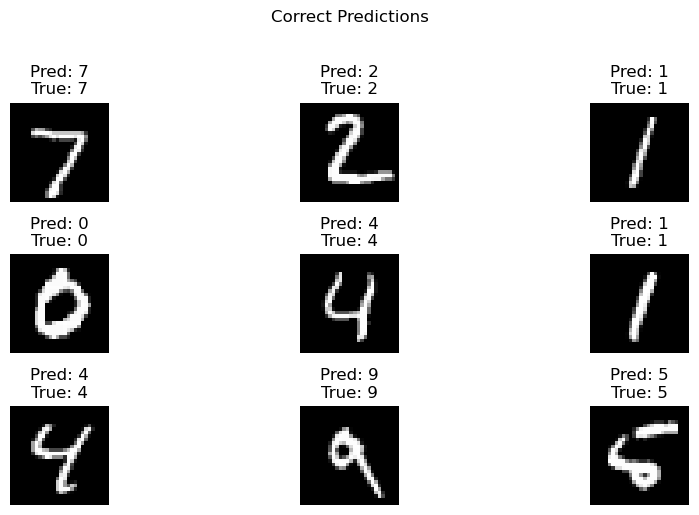

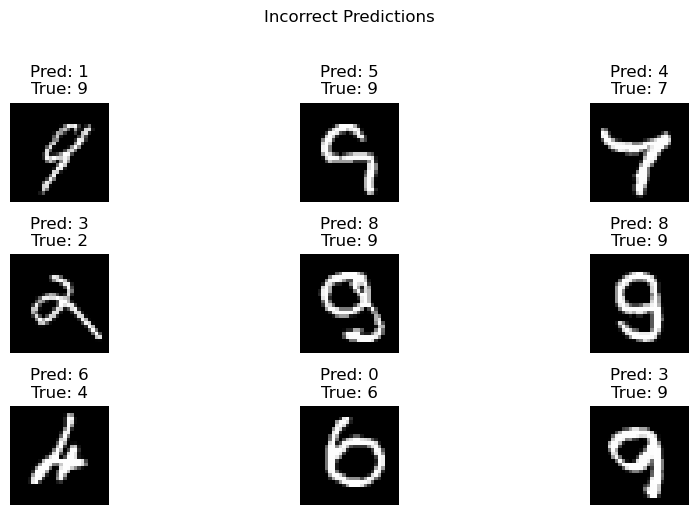

In [1]:
#测试1

# 1. 导入必要的库
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 2. 加载MNIST数据集
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 3. 数据预处理
# 数据归一化 (0-255 -> 0-1)
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# 将标签转换为one-hot编码
y_train_onehot = to_categorical(y_train, 10)
y_test_onehot = to_categorical(y_test, 10)

# 4. 构建模型（按照图1要求的结构）
model = Sequential()
model.add(Flatten(input_shape=(28, 28)))  # 输入层，将28x28图像转为784维向量
model.add(Dense(32, activation='relu'))   # 隐藏层1，32个神经元
model.add(Dense(16, activation='relu'))   # 隐藏层2，16个神经元
model.add(Dense(8, activation='relu'))    # 隐藏层3，8个神经元
model.add(Dense(10, activation='softmax')) # 输出层，10个神经元

# 5. 查看模型摘要
model.summary()

# 6. 编译模型
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# 7. 训练模型（迭代15次）
history = model.fit(x_train, y_train_onehot,
                    batch_size=32,
                    epochs=15,  # 按照要求训练15次
                    validation_split=0.2,
                    verbose=1)

# 8. 评估模型并打印测试集精度
test_loss, test_acc = model.evaluate(x_test, y_test_onehot, verbose=0)
print(f"\n测试集准确率: {test_acc:.4f}")

# 9. 绘制学习曲线
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='training acc')
plt.plot(history.history['val_accuracy'], label='validation acc')
plt.title('Accuracy Curve')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='training loss')
plt.plot(history.history['val_loss'], label='validation loss')
plt.title('Loss Curve')
plt.legend()
plt.show()

# 10. 预测测试集
predict_x = model.predict(x_test)
predicted_classes = np.argmax(predict_x, axis=1)

# 11. 可视化混淆矩阵
cm = confusion_matrix(y_test, predicted_classes)
labels = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

# 12. 可视化部分正确和错误的预测
correct_indices = np.nonzero(predicted_classes == y_test)[0]
incorrect_indices = np.nonzero(predicted_classes != y_test)[0]

# 正确预测的示例
plt.figure(figsize=(10, 5))
plt.suptitle('Correct Predictions', y=1.02)
for i, correct in enumerate(correct_indices[:9]):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_test[correct], cmap='gray', interpolation='none')
    plt.title(f"Pred: {predicted_classes[correct]}\nTrue: {y_test[correct]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

# 错误预测的示例
plt.figure(figsize=(10, 5))
plt.suptitle('Incorrect Predictions', y=1.02)
for i, incorrect in enumerate(incorrect_indices[:9]):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_test[incorrect], cmap='gray', interpolation='none')
    plt.title(f"Pred: {predicted_classes[incorrect]}\nTrue: {y_test[incorrect]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 27, 27, 64)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 13, 13, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 12, 12, 32)          │           8,224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 6, 6, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 5, 5, 16)            │           2,064 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 400)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 16)                  │           6,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 10)                  │              90 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 17,250 (67.38 KB)

 Trainable params: 17,250 (67.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 39ms/step - accuracy: 0.5775 - loss: 1.2054 - val_accuracy: 0.9367 - val_loss: 0.2152
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 14s 38ms/step - accuracy: 0.9415 - loss: 0.2001 - val_accuracy: 0.9623 - val_loss: 0.1377
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - accuracy: 0.9607 - loss: 0.1338 - val_accuracy: 0.9678 - val_loss: 0.1096
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 14s 38ms/step - accuracy: 0.9686 - loss: 0.1039 - val_accuracy: 0.9712 - val_loss: 0.1036
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.9736 - loss: 0.0847 - val_accuracy: 0.9766 - val_loss: 0.0831

测试集准确率: 0.9791


C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20934 (\N{CJK UNIFIED IDEOGRAPH-51C6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 30830 (\N{CJK UNIFIED IDEOGRAPH-786E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 29575 (\N{CJK UNIFIED IDEOGRAPH-7387}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  

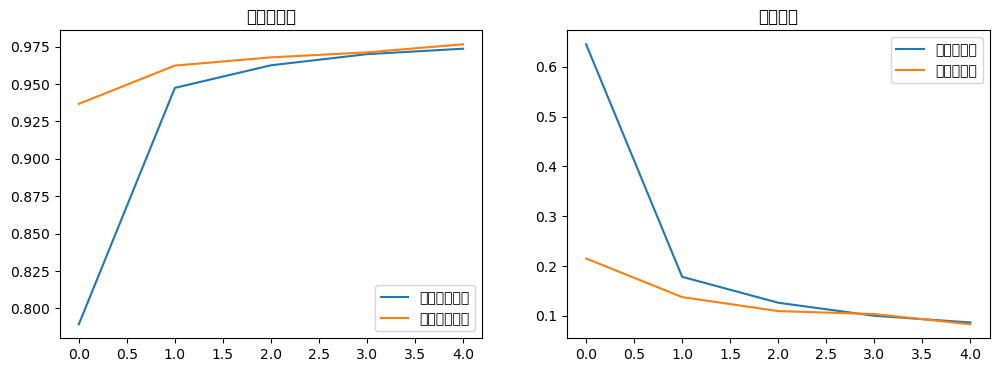

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


<Figure size 1000x800 with 0 Axes>

C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 28151 (\N{CJK UNIFIED IDEOGRAPH-6DF7}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 28102 (\N{CJK UNIFIED IDEOGRAPH-6DC6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 30697 (\N{CJK UNIFIED IDEOGRAPH-77E9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 38453 (\N{CJK UNIFIED IDEOGRAPH-9635}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


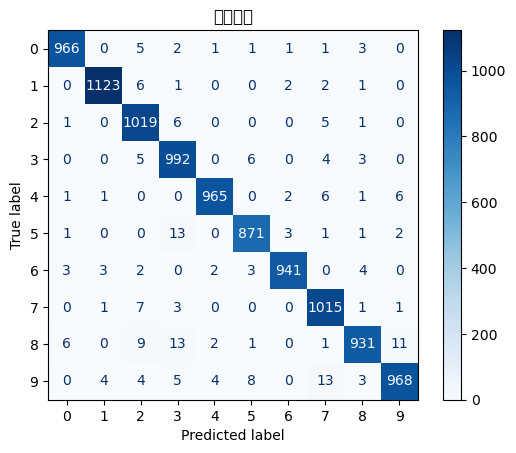

C:\Users\12518\AppData\Local\Temp\ipykernel_19972\2076779287.py:113: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_19972\2076779287.py:113: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_19972\2076779287.py:113: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_19972\2076779287.py:113: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_19972\2076779287.py:113: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_19972\2076779287.py:113: UserWarning: Glyph 30

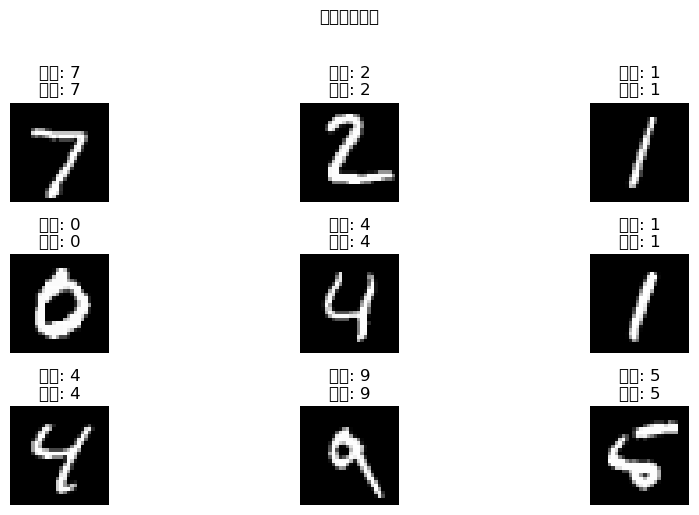

C:\Users\12518\AppData\Local\Temp\ipykernel_19972\2076779287.py:124: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_19972\2076779287.py:124: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_19972\2076779287.py:124: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_19972\2076779287.py:124: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_19972\2076779287.py:124: UserWarning: Glyph 38169 (\N{CJK UNIFIED IDEOGRAPH-9519}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_19972\2076779287.py:124: UserWarning: Glyph 35

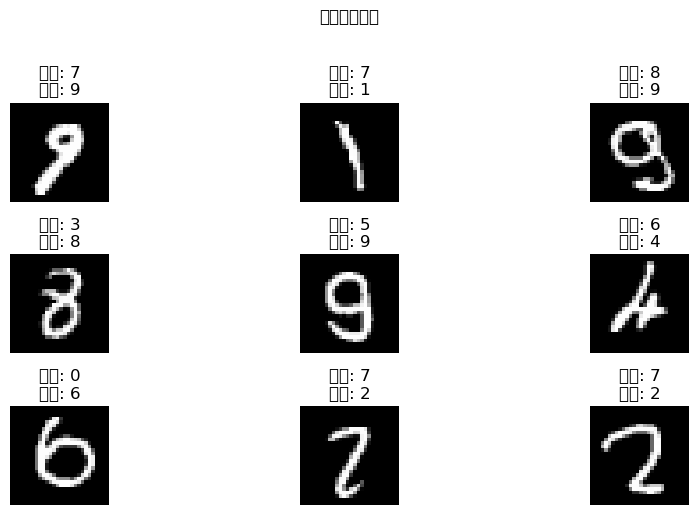

In [6]:
#测试2

# 1. 导入必要的库
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 2. 加载MNIST数据集
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 3. 数据预处理
# 数据归一化 (0-255 -> 0-1)并添加通道维度
x_train = x_train.astype('float32').reshape(-1, 28, 28, 1) / 255.0
x_test = x_test.astype('float32').reshape(-1, 28, 28, 1) / 255.0

# 将标签转换为one-hot编码
y_train_onehot = to_categorical(y_train, 10)
y_test_onehot = to_categorical(y_test, 10)

# 4. 构建CNN模型
model = Sequential()

# 卷积层1：64个2x2卷积核，ReLU激活
model.add(Conv2D(64, (2, 2), activation='relu', input_shape=(28, 28, 1)))

# 池化层1：2x2最大池化
model.add(MaxPooling2D((2, 2)))

# 卷积层2：32个2x2卷积核，ReLU激活
model.add(Conv2D(32, (2, 2), activation='relu'))

# 池化层2：2x2最大池化
model.add(MaxPooling2D((2, 2)))

# 卷积层3：16个2x2卷积核，ReLU激活
model.add(Conv2D(16, (2, 2), activation='relu'))

# 展平层
model.add(Flatten())

# 全连接层1：16个神经元，ReLU激活
model.add(Dense(16, activation='relu'))

# 全连接层2：8个神经元，ReLU激活
model.add(Dense(8, activation='relu'))

# 输出层：10个神经元，Softmax激活
model.add(Dense(10, activation='softmax'))

# 5. 查看模型摘要
model.summary()

# 6. 编译模型
model.compile(optimizer=Adam(),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# 7. 训练模型（5次迭代）
history = model.fit(x_train, y_train_onehot,
                    epochs=5,  # 按照要求训练5次
                    batch_size=128,
                    validation_split=0.2,
                    verbose=1)

# 8. 评估模型并打印测试集精度
test_loss, test_acc = model.evaluate(x_test, y_test_onehot, verbose=0)
print(f"\n测试集准确率: {test_acc:.4f}")

# 9. 绘制学习曲线
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='训练集准确率')
plt.plot(history.history['val_accuracy'], label='验证集准确率')
plt.title('准确率曲线')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='训练集损失')
plt.plot(history.history['val_loss'], label='验证集损失')
plt.title('损失曲线')
plt.legend()
plt.show()

# 10. 预测测试集
predictions = model.predict(x_test)
predicted_classes = np.argmax(predictions, axis=1)

# 11. 可视化混淆矩阵
cm = confusion_matrix(y_test, predicted_classes)
labels = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]

plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap=plt.cm.Blues)
plt.title('混淆矩阵')
plt.show()

# 12. 可视化部分预测结果
correct_indices = np.where(predicted_classes == y_test)[0]
incorrect_indices = np.where(predicted_classes != y_test)[0]

# 正确预测的示例
plt.figure(figsize=(10, 5))
plt.suptitle('正确预测示例', y=1.02)
for i, correct in enumerate(correct_indices[:9]):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_test[correct].reshape(28, 28), cmap='gray')
    plt.title(f"预测: {predicted_classes[correct]}\n真实: {y_test[correct]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

# 错误预测的示例
plt.figure(figsize=(10, 5))
plt.suptitle('错误预测示例', y=1.02)
for i, incorrect in enumerate(incorrect_indices[:9]):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_test[incorrect].reshape(28, 28), cmap='gray')
    plt.title(f"预测: {predicted_classes[incorrect]}\n真实: {y_test[incorrect]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

Epoch 1/200


C:\Users\12518\anaconda\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


413/413 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 1.5960 - mae: 0.8676 - val_loss: 0.5566 - val_mae: 0.5104
Epoch 2/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4984 - mae: 0.4611 - val_loss: 0.4075 - val_mae: 0.4448
Epoch 3/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.4043 - mae: 0.4470 - val_loss: 0.4015 - val_mae: 0.4479
Epoch 4/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3508 - mae: 0.4221 - val_loss: 0.3878 - val_mae: 0.4376
Epoch 5/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3468 - mae: 0.4180 - val_loss: 0.3713 - val_mae: 0.4192
Epoch 6/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3341 - mae: 0.4070 - val_loss: 0.3678 - val_mae: 0.4313
Epoch 7/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3325 - mae: 0.4083 - val_loss: 0.3519 - val_mae: 0.4110
Epoch 8/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3306 - mae: 0.4056 - val_loss: 0.3390 - val_mae: 0.4061
Epoch 9/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss:

C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25151 (\N{CJK UNIFIED IDEOGRAPH-623F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20215 (\N{CJK UNIFIED IDEOGRAPH-4EF7}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  

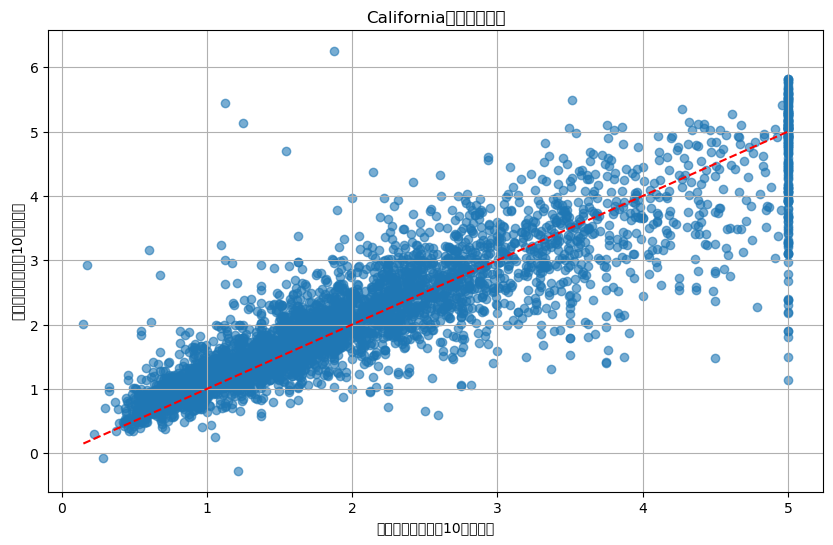

C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 39564 (\N{CJK UNIFIED IDEOGRAPH-9A8C}) missing from font(s) DejaVu Sans.
  

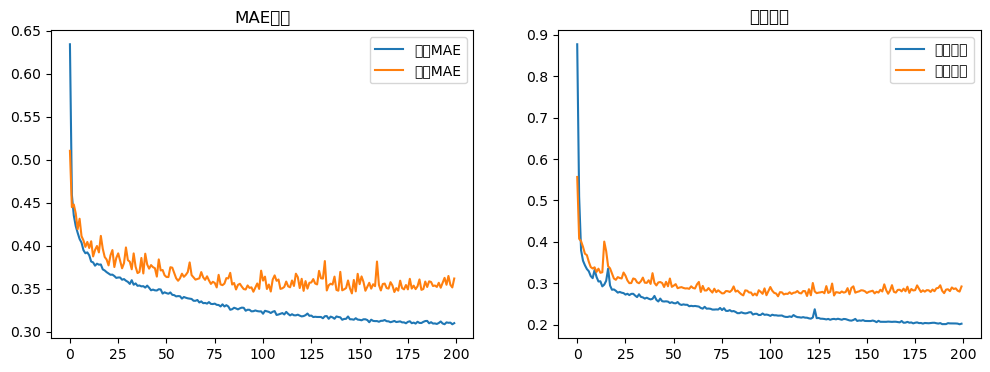

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# 1. 加载California Housing数据集
housing = fetch_california_housing()
X = housing.data
y = housing.target

# 2. 数据预处理
# 分割训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 特征标准化
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. 构建模型
model = Sequential()
model.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))  # 第一层64个神经元
model.add(Dense(32, activation='relu'))  # 第二层32个神经元
model.add(Dense(1))  # 输出层（回归问题不需要激活函数）

# 4. 编译模型
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='mse',
              metrics=['mae'])

# 5. 训练模型
history = model.fit(X_train, y_train,
                    epochs=200,  # 训练200轮
                    batch_size=32,
                    validation_split=0.2,
                    verbose=1)

# 6. 评估模型
test_loss, test_mae = model.evaluate(X_test, y_test, verbose=0)
print(f"\n测试集MAE: {test_mae:.4f}")

# 7. 预测测试集
y_pred = model.predict(X_test).flatten()

# 8. 可视化预测结果与真实值
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--')  # 理想预测线
plt.xlabel('真实房价（单位：10万美元）')
plt.ylabel('预测房价（单位：10万美元）')
plt.title('California房价预测结果')
plt.grid(True)
plt.show()

# 9. 绘制训练曲线
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['mae'], label='训练MAE')
plt.plot(history.history['val_mae'], label='验证MAE')
plt.title('MAE曲线')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='训练损失')
plt.plot(history.history['val_loss'], label='验证损失')
plt.title('损失曲线')
plt.legend()
plt.show()

Epoch 1/200


C:\Users\12518\anaconda\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 135ms/step - loss: 574.5121 - val_loss: 605.4311
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 516.4379 - val_loss: 553.1844
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 468.3997 - val_loss: 472.6373
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 425.6306 - val_loss: 426.0072
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 356.6069 - val_loss: 403.0104
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - loss: 328.0789 - val_loss: 387.6636
Epoch 7/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 341.4503 - val_loss: 374.8616
Epoch 8/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 310.8062 - val_loss: 363.6497
Epoch 9/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 281.4772 - val_loss: 353.4142
Epoch 10/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 320.3036 - val_loss: 343.8882
Epoch 11/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 283.4983 - val_loss: 335.3329
Epoch 12/200
11/11 

C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 27874 (\N{CJK UNIFIED IDEOGRAPH-6CE2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 22763 (\N{CJK UNIFIED IDEOGRAPH-58EB}) missing from font(s) DejaVu Sans.
  

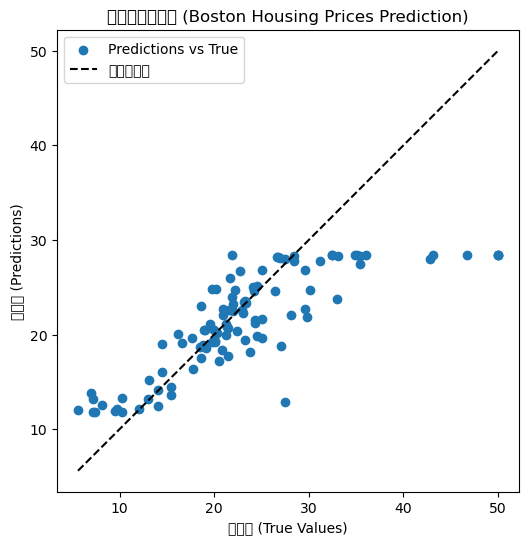

In [11]:
#测试3-2

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from tensorflow.keras.datasets import boston_housing
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt

# 加载波士顿房价数据集
(x_train, y_train), (x_test, y_test) = boston_housing.load_data()

# 数据标准化
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# 重塑数据为RNN输入格式 (样本数, 时间步长, 特征数)
x_train_reshaped = x_train_scaled.reshape((x_train_scaled.shape[0], 13, 1))
x_test_reshaped = x_test_scaled.reshape((x_test_scaled.shape[0], 13, 1))

# 构建RNN模型
model = Sequential()
model.add(SimpleRNN(30, input_shape=(13, 1), return_sequences=True))
model.add(SimpleRNN(20, return_sequences=False))
model.add(Dense(1))

# 编译模型
model.compile(loss='mean_squared_error', optimizer='adam')

# 训练模型
model.fit(x_train_reshaped, y_train, epochs=200, batch_size=32, validation_split=0.2)

# 在测试集上进行预测
y_pred = model.predict(x_test_reshaped)

# 可视化预测值与真实值
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, label='Predictions vs True')
plt.xlabel('真实值 (True Values)')
plt.ylabel('预测值 (Predictions)')
plt.title('波士顿房价预测 (Boston Housing Prices Prediction)')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', label='理想预测线')
plt.legend()
plt.axis('equal')
plt.axis('square')
plt.show()

Epoch 1/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 1.4965 - mae: 0.8563 - val_loss: 0.4672 - val_mae: 0.4819
Epoch 2/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.4120 - mae: 0.4560 - val_loss: 0.4051 - val_mae: 0.4498
Epoch 3/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3779 - mae: 0.4349 - val_loss: 0.3865 - val_mae: 0.4410
Epoch 4/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3547 - mae: 0.4188 - val_loss: 0.3748 - val_mae: 0.4261
Epoch 5/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3489 - mae: 0.4173 - val_loss: 0.3648 - val_mae: 0.4306
Epoch 6/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3326 - mae: 0.4046 - val_loss: 0.4056 - val_mae: 0.4392
Epoch 7/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.3636 - mae: 0.4118 - val_loss: 0.3505 - val_mae: 0.4157
Epoch 8/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.3191 - mae: 0.3941 - val_loss: 0.3503 - val_mae: 0.4258
Epoch 9/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 4s 10

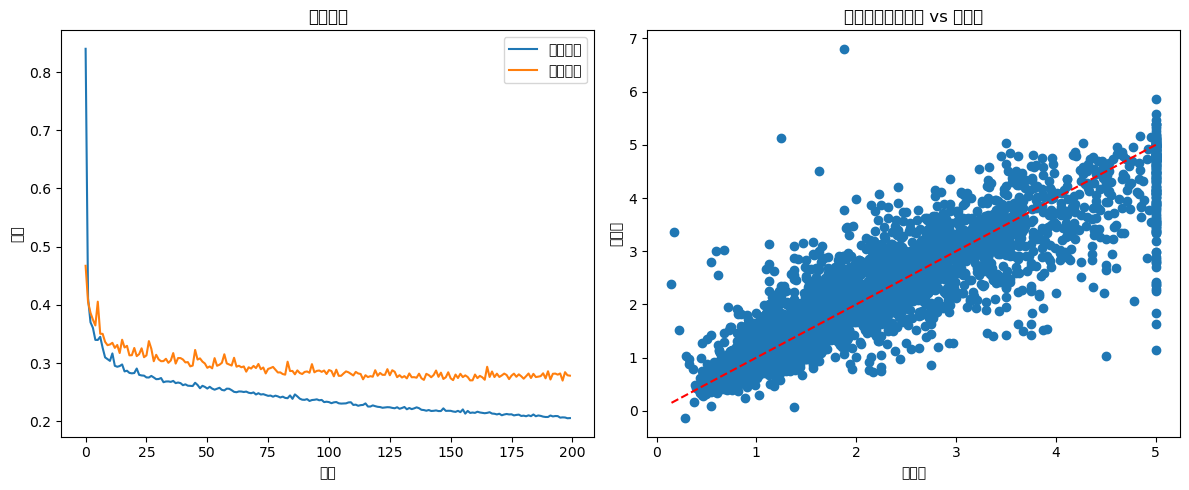

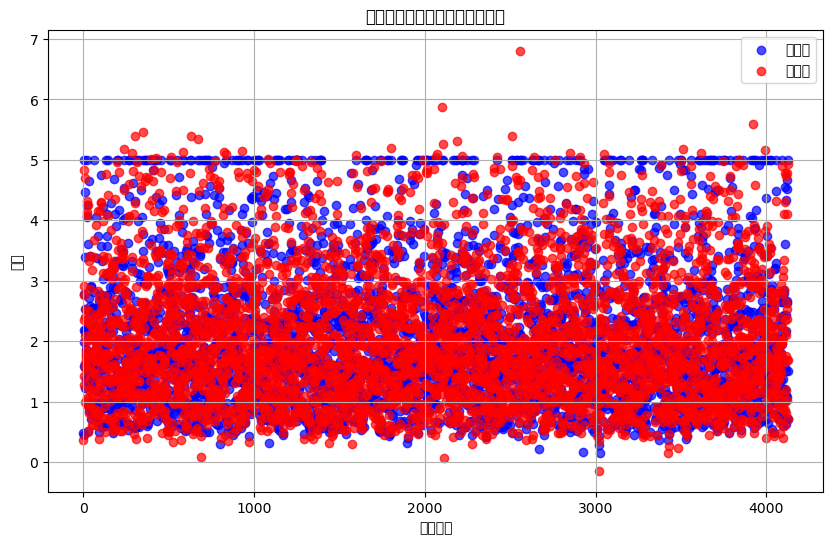

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import warnings

# 忽略警告
warnings.filterwarnings('ignore')

# 加载加州房价数据集，替代已移除的波士顿数据集
california = fetch_california_housing()
X = california.data
y = california.target

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 标准化特征
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 构建两层MLP模型
model = Sequential()
model.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))  # 第一层：64个神经元
model.add(Dense(32, activation='relu'))  # 第二层：32个神经元
model.add(Dense(1))  # 输出层

# 编译模型
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# 训练模型，训练轮数设为200
history = model.fit(X_train_scaled, y_train, epochs=200, batch_size=32, 
                   validation_split=0.2, verbose=1)

# 在测试集上进行预测
y_pred = model.predict(X_test_scaled)

# 评估模型性能
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"均方误差(MSE): {mse:.2f}")
print(f"决定系数(R²): {r2:.2f}")

# 可视化训练过程
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='训练损失')
plt.plot(history.history['val_loss'], label='验证损失')
plt.title('模型损失')
plt.xlabel('轮数')
plt.ylabel('损失')
plt.legend()

# 可视化测试数据上的预测值和真实值
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--')
plt.title('测试集上的预测值 vs 真实值')
plt.xlabel('真实值')
plt.ylabel('预测值')
plt.tight_layout()
plt.show()

# 可视化预测值和真实值的比较（按样本顺序）
plt.figure(figsize=(10, 6))
sample_indices = np.arange(len(y_test))
plt.scatter(sample_indices, y_test, label='真实值', color='blue', alpha=0.7)
plt.scatter(sample_indices, y_pred, label='预测值', color='red', alpha=0.7)
plt.title('测试集上的预测值和真实值比较')
plt.xlabel('样本索引')
plt.ylabel('房价')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# 加载波士顿房价数据集
# 由于sklearn已经移除了原始波士顿数据集，这里使用California房价数据集代替
housing = fetch_california_housing()
X = housing.data
y = housing.target

# 数据划分
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 数据标准化
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 构建双层MLP模型 (64-32)
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)  # 输出层，预测房价
])

# 编译模型
model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

# 模型摘要
model.summary()

# 训练模型
history = model.fit(
    X_train_scaled, y_train,
    epochs=200,  # 设置为200轮训练
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# 评估模型
test_loss, test_mae = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"测试集平均绝对误差 (MAE): {test_mae:.4f}")

# 预测值
y_pred = model.predict(X_test_scaled)

# 可视化训练过程
plt.figure(figsize=(12, 5))

# 损失函数曲线
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='训练损失')
plt.plot(history.history['val_loss'], label='验证损失')
plt.title('训练和验证损失')
plt.xlabel('轮次')
plt.ylabel('均方误差')
plt.legend()

# 可视化预测结果
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('真实值')
plt.ylabel('预测值')
plt.title('预测值 vs 真实值')

plt.tight_layout()
plt.show()

# 展示部分预测结果对比
sample_size = min(10, len(y_test))
indices = np.random.choice(len(y_test), sample_size, replace=False)

print("\n部分预测结果对比:")
print("索引\t真实值\t\t预测值\t\t误差")
print("-" * 50)
for i, idx in enumerate(indices):
    print(f"{idx}\t{y_test[idx]:.4f}\t\t{y_pred[idx][0]:.4f}\t\t{abs(y_test[idx] - y_pred[idx][0]):.4f}")

C:\Users\12518\anaconda\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             576 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 1.7716 - mae: 0.9396 - val_loss: 0.5271 - val_mae: 0.4997
Epoch 2/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4553 - mae: 0.4774 - val_loss: 0.4318 - val_mae: 0.4830
Epoch 3/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3905 - mae: 0.4404 - val_loss: 0.4012 - val_mae: 0.4465
Epoch 4/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3754 - mae: 0.4287 - val_loss: 0.3836 - val_mae: 0.4381
Epoch 5/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3307 - mae: 0.4096 - val_loss: 0.3751 - val_mae: 0.4272
Epoch 6/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3303 - mae: 0.4075 - val_loss: 0.3584 - val_mae: 0.4173
Epoch 7/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3338 - mae: 0.4064 - val_loss: 0.3498 - val_mae: 0.4118
Epoch 8/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3184 - mae: 0.3954 - val_loss: 0.3492 - val_mae: 0.4179
Epoch 9/200
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_boston
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np

# 1. 加载数据并预处理
boston = load_boston()
X = boston.data
y = boston.target.reshape(-1, 1)

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 标准化数据
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train = scaler_y.fit_transform(y_train)
y_test = scaler_y.transform(y_test)

# 转换为PyTorch张量
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)
y_train = torch.FloatTensor(y_train)
y_test = torch.FloatTensor(y_test)

# 2. 定义两层MLP模型
class BostonPredictor(nn.Module):
    def __init__(self, input_dim):
        super(BostonPredictor, self).__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# 3. 初始化模型、损失函数和优化器
input_dim = X_train.shape[1]
model = BostonPredictor(input_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 4. 训练模型
epochs = 200
train_losses = []
test_losses = []

for epoch in range(epochs):
    # 训练
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())
    
    # 测试
    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test)
        test_loss = criterion(test_outputs, y_test)
        test_losses.append(test_loss.item())
    
    if (epoch+1) % 20 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Train Loss: {loss.item():.4f}, Test Loss: {test_loss.item():.4f}')

# 5. 可视化训练过程
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Testing Loss')
plt.legend()
plt.show()

# 6. 在测试集上预测并可视化
model.eval()
with torch.no_grad():
    predictions = model(X_test)
    
# 反标准化
predictions = scaler_y.inverse_transform(predictions.numpy())
y_test_actual = scaler_y.inverse_transform(y_test.numpy())

# 可视化预测值与真实值
plt.figure(figsize=(10, 6))
plt.scatter(range(len(y_test_actual)), y_test_actual, color='blue', label='Actual Price')
plt.scatter(range(len(predictions)), predictions, color='red', label='Predicted Price')
plt.xlabel('Sample Index')
plt.ylabel('House Price')
plt.title('Boston Housing Prices: Actual vs Predicted')
plt.legend()
plt.show()